# The parity tier, closed: result files written in full

Every registered format now reads and writes in both engines. This notebook shows the last extensions of the result-file writers:

- **`vtx`** writes meshes of several cell types and of several parts (one block per type and part, the shared points marked as ghosts and welded back on read) and the `reuse` mesh policy.
- **`szplt`** writes each variable in the TecIO type that holds its dtype and tetrahedron and brick zones as partitioned zones (it needs a TecIO; the cells below say so when there is none).
- **`nastran_h5`** and **`nastran_op2`** write ply and station values, the composite and beam properties and the other materials, with the HDF5 tables completed to MSC's own column sets.
- **`xplt`** writes remeshed series: a new mesh section for every step whose mesh changed.

What is a fact of a format rather than an unwritten feature (64-bit and NX OP2 dialects, SZL polygon zones, complex `.rst` results, ...) is recorded in the roadmap's *Non-goals and decisions taken*.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import PolyCollection

os.environ.setdefault('MESHIOPLUSPLUS_LOG_LEVEL', 'error')
import meshioplusplus as mp  # noqa: E402

TMP = tempfile.mkdtemp()
MESHES = os.path.join(os.path.dirname(os.path.dirname(os.getcwd())), 'tests', 'python', 'meshes')
HAS_ADIOS2 = bool(getattr(mp._core, '__has_adios2__', False))
try:
    import adios2  # noqa: F401
    HAS_ADIOS2 = True
except ImportError:
    pass


def draw(ax, mesh, values=None, title='', cmap='viridis'):
    '''A 2-D mesh of triangles and quads as coloured polygons (matplotlib only, so it renders anywhere).'''
    polys, colours = [], []
    for block, cell_values in zip(mesh.cells, values if values is not None else [None] * len(mesh.cells)):
        for k, row in enumerate(block.data):
            polys.append(mesh.points[row][:, :2])
            colours.append(np.nan if cell_values is None else cell_values[k])
    coll = PolyCollection(polys, edgecolors='#333333', linewidths=0.8, cmap=cmap)
    coll.set_array(np.nan_to_num(np.array(colours, dtype=float), nan=0.0))
    ax.add_collection(coll)
    ax.set_xlim(mesh.points[:, 0].min() - 0.1, mesh.points[:, 0].max() + 0.1)
    ax.set_ylim(mesh.points[:, 1].min() - 0.1, mesh.points[:, 1].max() + 0.1)
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=10)
    ax.axis('off')

## `vtx`: several cell types in one file

DOLFINx writes one cell type per file. meshio++ writes a mesh of several as **one block per cell type**, each block holding the points its cells use. A point that two blocks share is a ghost copy in the later one (`vtkGhostType`, `vtkOriginalPointIds`), and the `meshio.shared_points` attribute tells the reader to weld the copies back, so the mesh reads back as it went in: the same points in the same order, the unused one included.

points : 8 of 8 (the unused point is kept)
blocks : [('triangle', 2), ('quad', 1), ('triangle', 1)]
same mesh: True


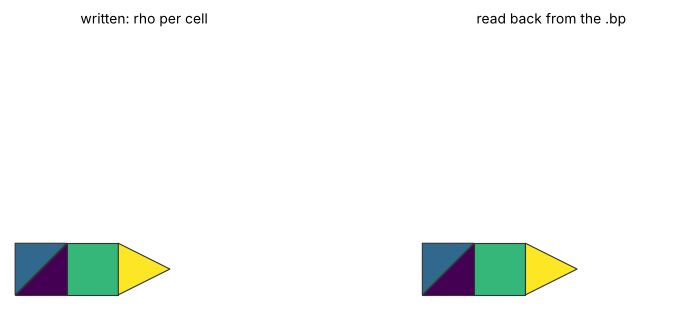

In [2]:
pts = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0], [2, 0, 0], [2, 1, 0], [3, 0.5, 0], [5, 5, 5]], dtype=float)
mixed = mp.Mesh(pts, [('triangle', np.array([[0, 1, 2], [0, 2, 3]])),
                      ('quad', np.array([[1, 4, 5, 2]])),
                      ('triangle', np.array([[4, 6, 5]]))],
                point_data={'u': pts[:, 0] * 2.0},
                cell_data={'rho': [np.array([1.0, 2.0]), np.array([3.0]), np.array([4.0])]})
if HAS_ADIOS2:
    out = os.path.join(TMP, 'mixed.bp')
    mp.write(out, mixed, file_format='vtx')
    back = mp.read(out)
    print('points :', len(back.points), 'of', len(mixed.points), '(the unused point is kept)')
    print('blocks :', [(c.type, len(c.data)) for c in back.cells])
    print('same mesh:', np.array_equal(back.points, mixed.points)
          and all(np.array_equal(a.data, b.data) for a, b in zip(back.cells, mixed.cells)))
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    draw(axes[0], mixed, mixed.cell_data['rho'], 'written: rho per cell')
    draw(axes[1], back, back.cell_data['rho'], 'read back from the .bp')
    plt.tight_layout()
    plt.show()
else:
    print('ADIOS2 is not installed: neither the core nor the adios2 package can write a .bp here.')

### Parts become blocks

A mesh whose cells carry `partition:part` (the [partitioner](../../doc/partition.md)'s array) is written one block per part and cell type, as DOLFINx writes one per rank. The cells come back grouped by part, the points in the mesh's own order.

points : 20 (one mesh, not one copy per part)
parts of the cells, as read: [0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2]


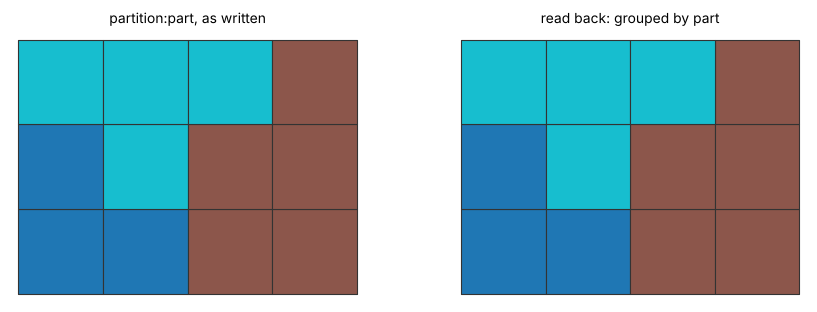

In [3]:
if HAS_ADIOS2:
    quads = []
    for j in range(3):
        for i in range(4):
            quads.append([j * 5 + i, j * 5 + i + 1, (j + 1) * 5 + i + 1, (j + 1) * 5 + i])
    gx, gy = np.meshgrid(np.arange(5.0), np.arange(4.0))
    grid = np.column_stack([gx.ravel(), gy.ravel(), np.zeros(gx.size)])
    part = np.array([0, 0, 1, 1, 0, 2, 1, 1, 2, 2, 2, 1])
    ranks = mp.Mesh(grid, [('quad', np.array(quads))], cell_data={'partition:part': [part]})
    out = os.path.join(TMP, 'parts.bp')
    mp.write(out, ranks, file_format='vtx')
    back = mp.read(out)
    print('points :', len(back.points), '(one mesh, not one copy per part)')
    print('parts of the cells, as read:', back.cell_data['partition:part'][0].tolist())
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
    draw(axes[0], ranks, [part], 'partition:part, as written', cmap='tab10')
    draw(axes[1], back, back.cell_data['partition:part'], 'read back: grouped by part', cmap='tab10')
    plt.tight_layout()
    plt.show()

### `VTXMeshPolicy.reuse`

`SeriesWriter(path, mesh_policy='reuse')` writes the mesh (and the ghost arrays) at the first step only, as DOLFINx does for a fixed mesh; the readers take the mesh of the last step that has one. A step with other points or cells is refused.

{'update': 40367, 'reuse': 38273}


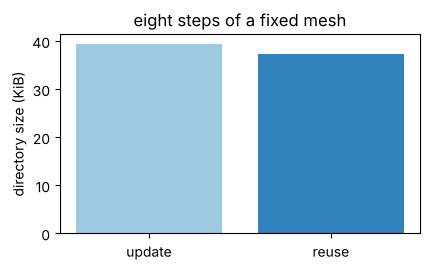

In [4]:
def directory_size(path):
    return sum(os.path.getsize(os.path.join(root, f)) for root, _, files in os.walk(path) for f in files)


if HAS_ADIOS2:
    sizes = {}
    for policy in ('update', 'reuse'):
        out = os.path.join(TMP, f'series_{policy}.bp')
        with mp.vtx.SeriesWriter(out, mesh_policy=policy) as writer:
            for step in range(8):
                step_mesh = mp.Mesh(grid, [('quad', np.array(quads))],
                                    point_data={'u': np.sin(grid[:, 0] + step)})
                writer.write(0.1 * step, step_mesh)
        sizes[policy] = directory_size(out)
        last = mp.read(out, time_step=7)
        assert np.array_equal(last.points, grid)
    print(sizes)
    fig, ax = plt.subplots(figsize=(4.4, 2.8))
    ax.bar(list(sizes), [v / 1024 for v in sizes.values()], color=['#9ecae1', '#3182bd'])
    ax.set_ylabel('directory size (KiB)')
    ax.set_title('eight steps of a fixed mesh')
    plt.tight_layout()
    plt.show()

## `szplt`: variable types and partitioned zones

Each variable is stored in the narrowest TecIO type that holds its array's dtype (`float32` stays single precision, `int16` and `int8` are 16-bit, `uint8` is a byte), and tetrahedron and brick zones whose cells carry `partition:part` are written as partitioned zones. TecIO joins the partitions on reading, so the mesh comes back with its points numbered partition by partition. TecIO is not redistributed: this section needs a core built with `MESHIOPLUSPLUS_WITH_TECIO` or `MESHIOPLUSPLUS_TECIO_LIBRARY`.

points : 20  cells: 4
rho    : [2.0, 4.0, 1.0, 3.0]  part: [0.0, 0.0, 1.0, 1.0]
T dtype after reading: float64 (TecIO stored single precision, the reader returns float64)


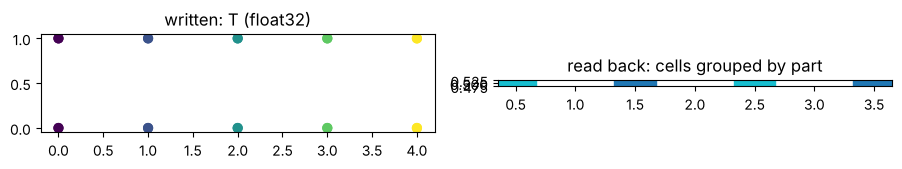

In [5]:
cube_pts, cubes = [], []
for i in range(5):
    for c in ([0, 0], [1, 0], [1, 1], [0, 1]):
        cube_pts.append([i, c[0], c[1]])
for i in range(4):
    cubes.append(list(range(i * 4, i * 4 + 4)) + list(range(i * 4 + 4, i * 4 + 8)))
cube_pts = np.array(cube_pts, dtype=float)
row = mp.Mesh(cube_pts, [('hexahedron', np.array(cubes))],
              point_data={'T': (cube_pts[:, 0] * 10).astype(np.float32), 'flag': (cube_pts[:, 0] > 2).astype(np.uint8)},
              cell_data={'partition:part': [np.array([1, 0, 1, 0])], 'rho': [np.array([1.0, 2.0, 3.0, 4.0])]})
out = os.path.join(TMP, 'row.szplt')
try:
    mp.write(out, row)
except Exception as exc:  # no TecIO in this environment
    print('szplt needs TecIO:', str(exc).splitlines()[0])
else:
    back = mp.read(out)
    print('points :', len(back.points), ' cells:', len(back.cells[0].data))
    print('rho    :', back.cell_data['rho'][0].tolist(), ' part:', back.cell_data['partition:part'][0].tolist())
    print('T dtype after reading:', back.point_data['T'].dtype, '(TecIO stored single precision, the reader returns float64)')
    centres = np.array([back.points[r].mean(axis=0) for r in back.cells[0].data])
    fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
    axes[0].scatter(cube_pts[:, 0], cube_pts[:, 1], c=row.point_data['T'], s=40)
    axes[0].set_title('written: T (float32)')
    axes[1].scatter(centres[:, 0], centres[:, 1] + 0.0, c=back.cell_data['partition:part'][0], s=900, marker='s', cmap='tab10')
    axes[1].set_title('read back: cells grouped by part')
    for ax in axes:
        ax.set_aspect('equal')
    plt.tight_layout()
    plt.show()

## `nastran_h5` and `nastran_op2`: plies, stations and the MSC schema

Ply values (`<G>:<M>@ply`) go to the `_COMP` tables with a `PLY` column and the composite's `PCOMP` property; station values (`<G>:<M>@station`) go to the `BARS` and `BEAM` tables. Every HDF5 table has MSC's own columns, order, types and defaults, taken from six real MSC Nastran 2020 files, and the result tables take MSC's names (`QUAD_CN`, `QUAD4_COMP`, `BARS`).

In [6]:
import h5py

plate_pts = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0], [2, 0, 0]], dtype=float)
layup = np.array([[1, 0.1, 0.0, 1], [1, 0.1, 45.0, 1], [1, 0.1, -45.0, 1], [1, 0.1, 90.0, 1]])
ply_stress = np.array([[120.0, 45.0, -30.0, -95.0]])
composite = mp.Mesh(
    plate_pts,
    [('quad', np.array([[0, 1, 2, 3]])), ('line', np.array([[1, 4]]))],
    cell_data={
        'nastran:eid': [np.array([1]), np.array([2])],
        'nastran:pid': [np.array([5]), np.array([6])],
        'nastran:card': [np.array([48]), np.array([24])],
        'nastran:x': [np.zeros((1, 3)), np.array([[0.0, 1.0, 0.0]])],
        'STRESS:X1@ply': [ply_stress, np.full((1, 4), np.nan)],
        'STRESS:X1': [np.array([ply_stress[0, 0]]), np.array([np.nan])],
        'FORCE:AXIAL@station': [np.full((1, 2), np.nan), np.array([[10.0, -4.0]])],
    },
    field_data={'nastran:PCOMP_5:PLY': layup, 'nastran:PCOMP_5:Z0': np.array([-0.2])},
)
h5_path = os.path.join(TMP, 'composite.h5')
mp.write(h5_path, composite, file_format='nastran_h5')
with h5py.File(h5_path) as f:
    tables = []
    f.visititems(lambda name, obj: tables.append(name) if isinstance(obj, h5py.Dataset) and not name.startswith('INDEX') else None)
    print('\n'.join(tables))
    print('PLY columns:', f['NASTRAN/INPUT/PROPERTY/PCOMP/PLY'].dtype.names)
back = mp.read(h5_path)
print('ply stresses read back:', back.cell_data['STRESS:X1@ply'][0].tolist() if back.cells[0].type == 'quad' else back.cell_data['STRESS:X1@ply'][1].tolist())

NASTRAN/INPUT/DOMAINS
NASTRAN/INPUT/ELEMENT/CBAR
NASTRAN/INPUT/ELEMENT/CQUAD4
NASTRAN/INPUT/MATERIAL/MAT1
NASTRAN/INPUT/NODE/GRID
NASTRAN/INPUT/PROPERTY/PBAR
NASTRAN/INPUT/PROPERTY/PCOMP/IDENTITY
NASTRAN/INPUT/PROPERTY/PCOMP/PLY
NASTRAN/RESULT/DOMAINS
NASTRAN/RESULT/ELEMENTAL/FORCE/BARS
NASTRAN/RESULT/ELEMENTAL/STRESS/QUAD4_COMP
NASTRAN/RESULT/ELEMENTAL/STRESS/QUAD_CN
PLY columns: ('MID', 'T', 'THETA', 'SOUT')
ply stresses read back: [[120.0, 45.0, -30.0, -95.0]]


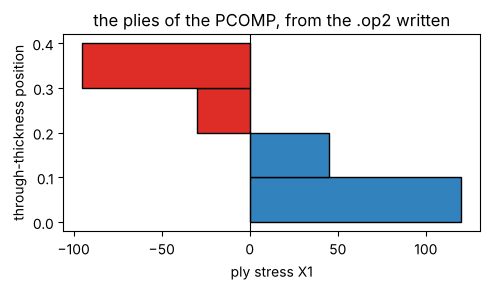

In [7]:
op2_path = os.path.join(TMP, 'composite.op2')
mp.write(op2_path, composite, file_format='nastran_op2')
from_op2 = mp.read(op2_path)
quad_block = [i for i, c in enumerate(from_op2.cells) if c.type == 'quad'][0]
plies = from_op2.cell_data['STRESS:X1@ply'][quad_block][0]
fig, ax = plt.subplots(figsize=(5, 3))
z = np.cumsum(np.r_[0, layup[:, 1]])
for k in range(4):
    ax.barh((z[k] + z[k + 1]) / 2, plies[k], height=layup[k, 1], color='#3182bd' if plies[k] > 0 else '#de2d26', edgecolor='k')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('ply stress X1')
ax.set_ylabel('through-thickness position')
ax.set_title('the plies of the PCOMP, from the .op2 written')
plt.tight_layout()
plt.show()

## `xplt`: remeshed series

FEBio's adaptive runs refine the mesh between steps, and its plot file then carries a new mesh section before the state. `xplt.SeriesWriter` (and `write_sequence`) now writes one for every step whose mesh differs from the previous one; the dictionary (variables, domains) must stay the same.

nodes per step, FEBio file : [12, 45, 78, 111]
nodes per step, rewritten  : [12, 45, 78, 111]


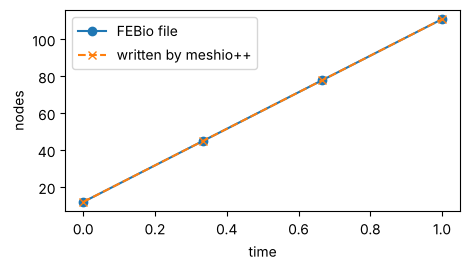

In [8]:
src = os.path.join(MESHES, 'febio', 'xplt', 'xplt_remesh.xplt')
if os.path.exists(src) and os.path.getsize(src) > 1000:
    steps = []
    for k, t in enumerate(mp.xplt.time_values(src)):
        steps.append((t, mp.read(src, time_step=k)))
    out = os.path.join(TMP, 'remeshed.xplt')
    mp.write_sequence(out, iter(steps), file_format='xplt')
    counts_in = [len(m.points) for _, m in steps]
    counts_out = [len(mp.read(out, time_step=k).points) for k in range(len(steps))]
    print('nodes per step, FEBio file :', counts_in)
    print('nodes per step, rewritten  :', counts_out)
    fig, ax = plt.subplots(figsize=(4.8, 2.8))
    ax.plot([t for t, _ in steps], counts_in, 'o-', label='FEBio file')
    ax.plot([t for t, _ in steps], counts_out, 'x--', label='written by meshio++')
    ax.set_xlabel('time')
    ax.set_ylabel('nodes')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('the FEBio remesh fixture is a Git LFS pointer here; run git lfs pull')